# BT4012 — Detecting Illicit Bitcoin Transactions

**e1156454** &nbsp;·&nbsp; [github.com/Violetloo/BT4012_Fraud](https://github.com/Violetloo/BT4012_Fraud)

This notebook rebuilds the final Kaggle submission from the four competition files: it loads
the data, builds the features, validates the models on time-based splits, and writes the CSV
that was uploaded. It imports nothing from the `src/` package, so it runs on a clean checkout
given only `train.csv`, `test.csv`, `txs_edgelist.csv` and `sample_submission.csv`.

### Score progression

| Submission | Public AUC |
|---|---|
| Competition baseline | 0.92119 |
| Gradient boosting on the raw features | 0.94351 |
| Adding component features | 0.94864 |
| Walks of 2, 3 and 4 steps | 0.95937 |
| PageRank propagation, α = 0.15 | 0.96034 |
| Three restart values mixed | 0.96057 |
| Six restart values | 0.96066 |
| Three restarts with 127 histogram bins | 0.96073 |
| Rank blend of the five | 0.96137 |

The classifier is unchanged from the third submission onwards: scikit-learn's histogram gradient
boosting with balanced class weights. Four hyperparameter searches produced one change worth
keeping, 127 bins instead of 255, so the improvement came from what the model was shown rather
than how it was configured.

Each transaction carries 165 anonymised features, which the competition describes as including
statistics over its immediate neighbours. One-step features built on top of those did not help,
while blocks summarising walks of two to four steps, and PageRank propagation mixing walk
lengths with a decay, moved the public score by about 0.012.

Runtime is roughly an hour, dominated by 40 validation fits (five configurations across eight
splits) and five final fits on all labelled rows.

### Running this notebook

Dependencies are pinned in `requirements.txt` at the repository root. The paths below assume the
notebook sits in `notebooks/` with the data in `data/`; adjust `DATA_DIR` and `OUT_DIR`
otherwise. Two optional cells at the end compare the generated file against earlier uploads and
skip themselves when those files are absent.

In [102]:
# Setup-
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import sparse
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 170)

# Where the four competition CSVs live: Path("data") when launched from the repository
# root, Path("../data") from inside notebooks/.
DATA_DIR = Path("../data")
OUT_DIR = Path("../submissions")
OUT_DIR.mkdir(exist_ok=True)

print(f"python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, "
      f"scipy {scipy.__version__}, scikit-learn {sklearn.__version__}")

python 3.13.7, numpy 2.2.6, pandas 2.3.2, scipy 1.16.2, scikit-learn 1.7.2


## 1. Loading the data

Unlabelled transactions have an empty `label` field rather than a word, so the column is parsed
explicitly and anything unexpected raises an error instead of becoming "unknown". With 78% of
training rows unlabelled, a silent coercion there would be easy to miss. File hashes are printed
so that a run can be tied to a particular copy of the data.

In [103]:
def parse_label(raw):
    """1 = illicit, 0 = licit, blank/none/unknown = not labelled; anything else is an error."""
    text = str(raw).strip().lower()
    if text in {"", "none", "unknown", "nan"}:
        return np.nan
    if text in {"0", "0.0"}:
        return 0.0
    if text in {"1", "1.0"}:
        return 1.0
    raise ValueError(f"Unexpected label value: {raw!r}")


def file_hash(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()[:16]


train = pd.read_csv(DATA_DIR / "train.csv", converters={"label": parse_label})
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
train["label"] = train["label"].astype(float)
edges.columns = ["src", "dst"]

for name in ["train.csv", "test.csv", "txs_edgelist.csv", "sample_submission.csv"]:
    print(f"{name:22s} sha256[:16] {file_hash(DATA_DIR / name)}")

print(f"\ntrain {train.shape}  steps {train.time_step.min()}-{train.time_step.max()}")
print(f"test  {test.shape}  steps {test.time_step.min()}-{test.time_step.max()}")
print(f"edges {len(edges):,}")
print(f"labels: {int((train.label == 0).sum()):,} licit, {int((train.label == 1).sum()):,} illicit, "
      f"{int(train.label.isna().sum()):,} unlabelled "
      f"({train.label.mean():.2%} illicit among the labelled)")

train.csv              sha256[:16] 6f7e56883f0aa271
test.csv               sha256[:16] 344e47c8cd8815f4
txs_edgelist.csv       sha256[:16] a35053ba68a98e43
sample_submission.csv  sha256[:16] 3dba74ad6151053a

train (141772, 168)  steps 1-35
test  (15329, 168)  steps 36-49
edges 234,355
labels: 27,591 licit, 3,644 illicit, 110,537 unlabelled (11.67% illicit among the labelled)


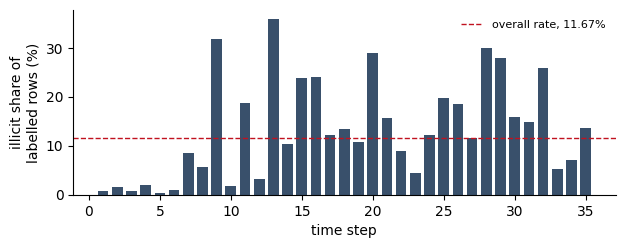

range: 0.4% at step 5 to 36.0% at step 13


In [104]:
# Illicit rate by time step: the reason validation has to run forward in time.
import matplotlib.pyplot as plt

rate = (train[train["label"].notna()]
        .groupby("time_step")["label"].mean() * 100)
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.bar(rate.index, rate.values, color="#39506b", width=0.75)
ax.axhline(11.67, color="#c1121f", ls="--", lw=1, label="overall rate, 11.67%")
ax.set_xlabel("time step"); ax.set_ylabel("illicit share of\nlabelled rows (%)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"range: {rate.min():.1f}% at step {rate.idxmin()} to {rate.max():.1f}% at step {rate.idxmax()}")

## 2. Inspection, and what was excluded

The files need no cleaning in the usual sense: no missing or infinite feature values, no constant
or duplicated columns, no repeated transaction IDs, no overlap between train and test IDs. The
cell below runs these as assertions rather than leaving them as prose, along with the property
the validation design depends on, that every edge with both endpoints in the data lies inside a
single time step.

Three decisions follow from the inspection.

1. **Six features track time closely and were removed.** The per-step means of `feat_100`,
   `feat_101`, `feat_103`, `feat_136`, `feat_137` and `feat_139` correlate with the time step at
   Spearman 0.992 to 1.000, and for the first three more than 99% of test values exceed anything
   seen in training. A tree cannot split usefully beyond its fitted range, so those rows fall
   into a single extreme bin. Removing all six leaves 159 predictors.

2. **`txId` and `time_step` are never predictors.** The time step only determines which rows
   belong to which split.

3. **Unlabelled rows are excluded from fitting and from scoring**, and are never treated as
   licit. They remain available as graph nodes, subject to the coverage rule in section 3.

Forty-four rows across thirteen groups share identical feature vectors. No group has conflicting
labels or spans two time steps, so all were kept: two distinct transactions can look the same
once the features are anonymised.

In [105]:
# The checks behind the claims above, run rather than asserted in prose.
ALL_FEATS = [c for c in train.columns if c.startswith("feat_")]

assert train["txId"].is_unique and test["txId"].is_unique, "duplicate transaction IDs"
assert not set(train["txId"]) & set(test["txId"]), "train and test share transaction IDs"
assert np.isfinite(train[ALL_FEATS].to_numpy()).all(), "non-finite values in train features"
assert np.isfinite(test[ALL_FEATS].to_numpy()).all(), "non-finite values in test features"
assert train[ALL_FEATS].isna().sum().sum() == 0, "missing values in train features"
assert train["time_step"].max() < test["time_step"].min(), "train and test periods overlap"

step_of = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId")["time_step"]
known = edges[edges["src"].isin(step_of.index) & edges["dst"].isin(step_of.index)]
cross = (step_of.loc[known["src"]].to_numpy() != step_of.loc[known["dst"]].to_numpy()).sum()
assert cross == 0, f"{cross} edges cross a time step; the time-based split would separate an edge"
print(f"edges with both endpoints known: {len(known):,}; of those, crossing a time step: {cross}")

dupes = train.duplicated(subset=ALL_FEATS, keep=False)
groups = train[dupes].groupby(ALL_FEATS, sort=False)
conflicts = int((groups["label"].nunique() > 1).sum())
assert conflicts == 0, f"{conflicts} duplicate-feature groups carry conflicting labels"
print(f"rows sharing a feature vector: {int(dupes.sum())} in {groups.ngroups} groups; "
      f"groups with conflicting labels: {conflicts}")
print("All structural checks passed.")

edges with both endpoints known: 175,918; of those, crossing a time step: 0
rows sharing a feature vector: 44 in 13 groups; groups with conflicting labels: 0
All structural checks passed.


In [106]:
TIME_ENCODING = ["feat_100", "feat_101", "feat_103", "feat_136", "feat_137", "feat_139"]
RAW = [c for c in train.columns if c.startswith("feat_") and c not in TIME_ENCODING]

evidence = pd.DataFrame({
    "train_max": train[TIME_ENCODING].max(),
    "test_max": test[TIME_ENCODING].max(),
    "share_of_test_above_train_max": [(test[c] > train[c].max()).mean() for c in TIME_ENCODING],
    "spearman_with_time_step": [train[["time_step", c]].corr(method="spearman").iloc[0, 1]
                                for c in TIME_ENCODING],
})
print(evidence.round(3).to_string())
print(f"\nKeeping {len(RAW)} of the 165 supplied features")

          train_max  test_max  share_of_test_above_train_max  spearman_with_time_step
feat_100      0.737     1.641                          0.992                    0.992
feat_101      0.738     1.658                          0.995                    0.997
feat_103      0.740     1.657                          0.994                    0.995
feat_136      4.124     3.408                          0.000                    0.994
feat_137      3.485     3.485                          0.000                    0.896
feat_139      3.974     3.273                          0.000                    0.954

Keeping 159 of the 165 supplied features


## 3. Features built from the transaction graph

### Which nodes contribute

Test transactions are missing roughly 39% of their neighbours' feature rows, because those
transactions are absent from the files, while training transactions would have all of theirs if
every row were allowed to contribute. The same column would then mean different things in the
two periods. Only usable nodes therefore supply feature vectors to propagation: labelled
training rows and test rows. What matters is whether a label exists, not what the label says.
The alternatives were tested later, admitting unlabelled rows and relaying values through nodes
with no features, and both scored lower.

### Component features

The size of the connected component containing each transaction, the share of that component
with usable feature rows, and degree relative to component size. These use the complete edge
list, including the 46,668 nodes without a feature row, since those still determine how large a
component is. Every edge lies inside one time step, so components never span periods.

### PageRank propagation

`H ← (1−α)·P·H + α·X`, run ten times from `H₀ = X`, with `P` the row-normalised adjacency
matrix. Each pass replaces a transaction's features with a mix of its own and the average over
its neighbours, retaining a fraction α of the original, so the result blends walk lengths with a
decay. Six restart values are built (0.05 to 0.30), since mixing several outperformed any single
one on the leaderboard.

Running the iteration closer to convergence performed worse: 30 and 100 iterations lost 0.005 to
0.009 on the long horizons. Ten iterations is far from converged, as the coefficient left on the
ten-step term is 0.60 at α = 0.05, but the less converged representation carried more signal.

### Walks of two to four steps

`P²X`, `P³X`, `P⁴X`. These are walks rather than shortest paths, so a two-step walk can return to
its starting transaction, meaning the blocks reuse nearby information as well as reaching
further out. The one-step block is deliberately excluded; including it cost 0.0016 publicly,
which is consistent with the supplied features already containing one-hop statistics.

Nodes with no usable neighbour receive missing values rather than zeros, since zero is a
meaningful feature value here. This affects 21.8% of labelled training rows and 25.4% of test
rows, and histogram gradient boosting handles missing values natively, so nothing is imputed.

In [107]:
def graph_setup(train, test, edges, feature_cols):
    """Combine train and test into one node table and select the usable edges.

    Returns the node table, the feature matrix, and both ends of each usable edge as row
    positions.
    """
    nodes = pd.concat([train[["txId", "time_step", "label"] + feature_cols],
                       test[["txId", "time_step"] + feature_cols].assign(label=1.0)],
                      ignore_index=True)
    # Usable rows: labelled training rows plus all test rows (see the coverage note above).
    usable = nodes["label"].notna().to_numpy()
    pos = pd.Series(np.arange(len(nodes)), index=nodes["txId"].values)
    e = edges[edges["src"].isin(pos.index) & edges["dst"].isin(pos.index)]
    si, di = pos.loc[e["src"]].to_numpy(), pos.loc[e["dst"]].to_numpy()
    keep = usable[si] & usable[di]
    return nodes, nodes[feature_cols].to_numpy("float32"), si[keep], di[keep]


def transition_matrix(si, di, n):
    """Row-normalised adjacency, treated as undirected: row i averages over i's neighbours."""
    rows, cols = np.r_[si, di], np.r_[di, si]
    A = sparse.coo_matrix((np.ones(len(rows), "float32"), (rows, cols)), shape=(n, n)).tocsr()
    deg = np.asarray(A.sum(axis=1)).ravel()
    inv = np.zeros_like(deg)
    inv[deg > 0] = 1.0 / deg[deg > 0]      # isolated nodes keep a zero row
    return sparse.diags(inv.astype("float32")) @ A, deg


nodes, X, SI, DI = graph_setup(train, test, edges, RAW)
P, DEG = transition_matrix(SI, DI, len(nodes))
IDX = pd.Index(nodes["txId"].values, name="txId")
print(f"{len(nodes):,} nodes, {len(SI):,} usable edges, "
      f"{(DEG == 0).sum():,} nodes with no usable neighbour")

157,101 nodes, 36,624 usable edges, 121,227 nodes with no usable neighbour


In [108]:
# Component features.
# Union-find over the complete edge list. The transaction IDs are not contiguous, so this
# avoids relabelling them for scipy.sparse.csgraph.
def component_features(edges, node_ids, usable_ids):
    all_ids = pd.unique(pd.concat([edges["src"], edges["dst"], pd.Series(node_ids)]))
    pos = pd.Series(np.arange(len(all_ids)), index=all_ids)
    parent = np.arange(len(all_ids))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]   # path halving
            a = parent[a]
        return a

    for u, v in zip(pos.loc[edges["src"]].to_numpy(), pos.loc[edges["dst"]].to_numpy()):
        ru, rv = find(u), find(v)
        if ru != rv:
            parent[ru] = rv
    root = np.array([find(i) for i in range(len(all_ids))])

    df = pd.DataFrame({"root": root, "usable": pd.Index(all_ids).isin(usable_ids)})
    size = df.groupby("root")["usable"].size()
    share = df.groupby("root")["usable"].mean()
    degree = pd.concat([edges["src"], edges["dst"]]).value_counts()

    rows = pos.loc[node_ids].to_numpy()
    out = pd.DataFrame(index=pd.Index(node_ids, name="txId"))
    out["cmp_size"] = df["root"].map(size).to_numpy()[rows]
    out["cmp_usable_share"] = df["root"].map(share).to_numpy()[rows]
    out["cmp_degree_over_size"] = (pd.Index(node_ids).map(degree).fillna(0).to_numpy()
                                   / out["cmp_size"].to_numpy())
    return out.astype("float32")


usable_ids = set(nodes.loc[nodes["label"].notna(), "txId"])
cmp_feats = component_features(edges, nodes["txId"].to_numpy(), usable_ids)
print(cmp_feats.describe().round(3).to_string())

         cmp_size  cmp_usable_share  cmp_degree_over_size
count  157101.000        157101.000            157101.000
mean     4726.982             0.225                 0.001
std      1588.922             0.054                 0.001
min      1089.000             0.112                 0.000
25%      3537.000             0.181                 0.000
50%      4528.000             0.240                 0.000
75%      5894.000             0.271                 0.001
max      7880.000             0.429                 0.087


In [109]:
# PageRank propagation and the 2/3/4-step walk blocks.
def ppr_features(X, P, deg, index, cols, alpha, prefix, iters=10):
    """PageRank-style propagation. Ten iterations: longer runs scored worse (section 3)."""
    H = X.copy()
    for _ in range(iters):
        H = (1 - alpha) * (P @ H) + alpha * X
    out = pd.DataFrame(H, index=index, columns=[f"{prefix}{c}" for c in cols])
    # No usable neighbour means the propagated value carries no information, so it is left
    # missing. HistGradientBoostingClassifier handles NaN natively.
    out[deg == 0] = np.nan
    return out.astype("float32")


def hop_features(X, P, deg, index, cols, hops=(2, 3, 4)):
    """Walks of exactly 2, 3 and 4 steps; the 1-step block is excluded (section 3)."""
    blocks, H = {}, X
    for hop in range(1, max(hops) + 1):
        H = P @ H
        if hop in hops:
            frame = pd.DataFrame(H, index=index, columns=[f"p{hop}_{c}" for c in cols])
            frame[deg == 0] = np.nan
            blocks[hop] = frame.astype("float32")
    return pd.concat(blocks.values(), axis=1)


ALPHAS = {"ppr_": 0.15, "ppr05_": 0.05, "ppr30_": 0.30,
          "pprf10_": 0.10, "pprf20_": 0.20, "pprf25_": 0.25}
ppr_blocks = {prefix: ppr_features(X, P, DEG, IDX, RAW, alpha=a, prefix=prefix)
              for prefix, a in ALPHAS.items()}
hops = hop_features(X, P, DEG, IDX, RAW)
print(f"{len(ppr_blocks)} PageRank blocks, {ppr_blocks['ppr_'].shape[1]} columns each")
print(f"walk block: {hops.shape[1]} columns")
# The overall missing rate counts the 110,537 unlabelled training rows, which are never
# fitted or scored. The rates that describe the model's actual inputs are reported per group.
_lab = set(train.loc[train["label"].notna(), "txId"])
_blk = ppr_blocks["ppr_"]
print(f"missing rate, all nodes:        {_blk.isna().mean().mean():.1%} "
      f"(includes unlabelled training rows, which are excluded from fitting)")
print(f"missing rate, labelled train:   {_blk.loc[list(_lab)].isna().mean().mean():.1%}")
print(f"missing rate, test rows:        {_blk.loc[test['txId']].isna().mean().mean():.1%}")

6 PageRank blocks, 159 columns each
walk block: 477 columns
missing rate, all nodes:        77.2% (includes unlabelled training rows, which are excluded from fitting)
missing rate, labelled train:   21.8%
missing rate, test rows:        25.4%


In [110]:
# The four feature sets behind the five models.
graph_block = pd.concat([cmp_feats] + list(ppr_blocks.values()) + [hops], axis=1)
train_f = train.join(graph_block, on="txId")
test_f = test.join(graph_block, on="txId")

CMP = list(cmp_feats.columns)
cols_of = lambda prefix: list(ppr_blocks[prefix].columns)
FEATURES = {
    "ppr_cmp":            RAW + cols_of("ppr_") + CMP,
    "prop34_cmp":         RAW + list(hops.columns) + CMP,
    "ppr_multi_cmp":      RAW + cols_of("ppr_") + cols_of("ppr05_") + cols_of("ppr30_") + CMP,
    "ppr_fine_multi_cmp": RAW + cols_of("ppr_") + cols_of("ppr05_") + cols_of("ppr30_")
                              + cols_of("pprf10_") + cols_of("pprf20_") + cols_of("pprf25_") + CMP,
}
for name, cols in FEATURES.items():
    print(f"{name:20s} {len(cols):5d} features")

ppr_cmp                321 features
prop34_cmp             639 features
ppr_multi_cmp          639 features
ppr_fine_multi_cmp    1116 features


## 4. Validation design

Training covers steps 1 to 35 and test covers 36 to 49, so every split predicts later periods
from earlier ones. Shuffled k-fold would expose future information and produces implausibly high
scores on this data.

Four short folds train on steps 1–15, 1–20, 1–25 and 1–30 and score the following five steps.
Four long horizons train on 1–15, 1–18, 1–21 and 1–24 and score the remainder up to step 35.
The long horizons overlap heavily in the rows they cover, and h24 spans 11 steps rather than 14,
so their mean is reported separately from the fold mean rather than averaged across all eight.

Unlabelled rows never enter fitting or scoring. Because every edge between known transactions
lies inside one time step, a time-based split cannot separate the two ends of an edge, which is
the usual source of leakage in graph problems.

On class weighting: `class_weight="balanced"` makes each class contribute to the loss in inverse
proportion to its frequency, so an illicit row carries roughly eight times the weight of a licit
one. It was tested rather than assumed. On the 22–35 horizon it moved histogram gradient
boosting from 0.8988 to 0.9151 and random forests from 0.8092 to 0.8868, but took XGBoost from
0.8800 down to 0.8630, so it was applied per model family.

The ensemble is evaluated here as well as its five members: within each split all five models are
fitted on that split's training rows, and the nested blending used for the submission is applied
to their validation predictions.

In [111]:
# Four short folds, then the four long horizons the report's "long-horizon mean" uses.
# The long horizons overlap heavily in the rows they score, so their mean is not an
# average of independent estimates and is reported separately from the fold mean.
FOLDS = [("fold1", (1, 15), (16, 20)), ("fold2", (1, 20), (21, 25)),
         ("fold3", (1, 25), (26, 30)), ("fold4", (1, 30), (31, 35))]
LONG = [("h15", (1, 15), (16, 29)), ("h18", (1, 18), (19, 32)),
        ("h21", (1, 21), (22, 35)), ("h24", (1, 24), (25, 35))]
SPLITS = FOLDS + LONG

# The five models: four feature sets at the default 255 bins, plus ppr_multi_cmp at 127
# bins, the only hyperparameter change that improved the score.
MODELS = [("ppr_cmp", "ppr_cmp", 255),
          ("prop34_cmp", "prop34_cmp", 255),
          ("ppr_multi_cmp", "ppr_multi_cmp", 255),
          ("ppr_fine_multi_cmp", "ppr_fine_multi_cmp", 255),
          ("ppr_multi_cmp_bins127", "ppr_multi_cmp", 127)]


def make_model(max_bins=255):
    """The final model. Fixed settings rather than library defaults; early stopping is
    disabled so the number of trees is fixed and the model refitted on all labelled rows is
    the same configuration that was evaluated during validation, refitted on more rows."""
    return HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=20,
        l2_regularization=0.0, max_bins=max_bins, early_stopping=False,
        class_weight="balanced", random_state=SEED)


def rank01(p):
    """Ranks scaled into (0, 1); tied predictions share a rank."""
    return rankdata(p) / (len(p) + 1)


def blend(preds):
    """The submitted ensemble, in the order the blends were built and scored on Kaggle.

    Each stage re-ranks the previous blend, so this is not equivalent to one weighted
    average of the five original rank vectors; the nesting is kept exactly as submitted.
    """
    pair       = 0.5  * rank01(preds["ppr_cmp"]) + 0.5  * rank01(preds["prop34_cmp"])
    with_multi = 2/3  * rank01(pair)             + 1/3  * rank01(preds["ppr_multi_cmp"])
    with_fine  = 0.75 * rank01(with_multi)       + 0.25 * rank01(preds["ppr_fine_multi_cmp"])
    return       0.75 * rank01(with_fine)        + 0.25 * rank01(preds["ppr_multi_cmp_bins127"])

In [112]:
def validate(frame, models, features, splits=SPLITS):
    """Fit every model on each split and score both the members and the blend."""
    labelled = frame[frame["label"].notna()]
    auc_rows, ap_rows, saved = [], [], []
    for name, (tr_lo, tr_hi), (va_lo, va_hi) in splits:
        tr = labelled[labelled["time_step"].between(tr_lo, tr_hi)]
        va = labelled[labelled["time_step"].between(va_lo, va_hi)]
        assert tr["time_step"].max() < va["time_step"].min(), f"{name}: validation is not strictly later"
        assert not set(tr["txId"]) & set(va["txId"]), f"{name}: a transaction appears on both sides"
        y = va["label"].to_numpy()
        assert len(np.unique(y)) == 2, f"{name}: validation block does not contain both classes"
        preds = {}
        for label, fs, bins in models:
            model = make_model(bins).fit(tr[features[fs]], tr["label"].astype(int))
            preds[label] = model.predict_proba(va[features[fs]])[:, 1]
        preds["ENSEMBLE"] = blend(preds)       # same nesting as the submission
        # keep row-level predictions so later checks do not need a retrain
        saved.append(pd.DataFrame({"split": name, "txId": va["txId"].to_numpy(),
                                   "time_step": va["time_step"].to_numpy(),
                                   "label": y, **preds}))
        auc_rows.append({"split": name, "n_val": len(va), "n_illicit": int(y.sum()),
                         **{k: roc_auc_score(y, p) for k, p in preds.items()}})
        ap_rows.append({"split": name, **{k: average_precision_score(y, p) for k, p in preds.items()}})
        print(f"  {name:8s} ensemble AUC {auc_rows[-1]['ENSEMBLE']:.4f}  "
              f"(best member {max(auc_rows[-1][k] for k, _, _ in models):.4f})")

    auc = pd.DataFrame(auc_rows).set_index("split")
    ap = pd.DataFrame(ap_rows).set_index("split")
    cols = [k for k, _, _ in models] + ["ENSEMBLE"]
    fold_names = [s[0] for s in splits if s[0].startswith("fold")]
    long_names = [s[0] for s in splits if s[0].startswith("h")]
    for tab in (auc, ap):
        tab.loc["fold mean (4 short folds)", cols] = tab.loc[fold_names, cols].mean()
        if long_names:
            tab.loc["long-horizon mean (4 overlapping)", cols] = tab.loc[long_names, cols].mean()
            tab.loc["worst long horizon", cols] = tab.loc[long_names, cols].min()
    return auc, ap, pd.concat(saved, ignore_index=True)


print(f"Fitting {len(MODELS) * len(SPLITS)} validation models "
      f"({len(MODELS)} configurations x {len(SPLITS)} splits) ...")
auc_table, ap_table, VALIDATION_PREDICTIONS = validate(train_f, MODELS, FEATURES)
print("\n=== ROC AUC by split ===")
print(auc_table.drop(columns=["n_val", "n_illicit"]).round(4).to_string())
print("\n=== Average precision by split ===")
print(ap_table.round(4).to_string())

# row-level validation predictions, for verification without retraining
VALIDATION_PREDICTIONS.to_csv(OUT_DIR / "e1156454_validation_predictions.csv", index=False)
print(f"\nsaved {len(VALIDATION_PREDICTIONS):,} row-level validation predictions to "
      f"{OUT_DIR / 'e1156454_validation_predictions.csv'}")

Fitting 40 validation models (5 configurations x 8 splits) ...
  fold1    ensemble AUC 0.9918  (best member 0.9919)
  fold2    ensemble AUC 0.9611  (best member 0.9631)
  fold3    ensemble AUC 0.9943  (best member 0.9948)
  fold4    ensemble AUC 0.9985  (best member 0.9986)
  h15      ensemble AUC 0.9451  (best member 0.9490)
  h18      ensemble AUC 0.9092  (best member 0.9180)
  h21      ensemble AUC 0.9035  (best member 0.9112)
  h24      ensemble AUC 0.9965  (best member 0.9967)

=== ROC AUC by split ===
                                   ppr_cmp  prop34_cmp  ppr_multi_cmp  ppr_fine_multi_cmp  ppr_multi_cmp_bins127  ENSEMBLE
split                                                                                                                     
fold1                               0.9903      0.9914         0.9913              0.9912                 0.9919    0.9918
fold2                               0.9631      0.9610         0.9606              0.9616                 0.9576    0.

## 5. Results

Development results alongside the leaderboard scores they produced:

| Feature set | Fold mean AUC | Public AUC |
|---|---|---|
| raw features only (159) | 0.9830 | 0.94351 |
| + component features | 0.9826 | 0.94864 |
| + 1- and 2-step propagation | 0.9821 | 0.95670 |
| walks of 2, 3 and 4 steps | 0.9865 | 0.95937 |
| PageRank, α = 0.15 | 0.9866 | 0.96034 |
| three restarts | 0.9859 | 0.96057 |
| six restarts | 0.9863 | 0.96066 |
| three restarts, 127 bins | 0.9854 | 0.96073 |
| rank blend of the five | 0.9864 | 0.96137 |

Two findings shaped the approach.

The first is that local scores and leaderboard scores barely relate. The third row is typical:
adding 1- and 2-step propagation lowered the fold mean and raised the public score by 0.008.
Nine candidates fixed in advance and submitted together gave a rank correlation of 0.00 between
their long-horizon mean and their public score, and six later configurations improved every
local metric before losing on test. Validation was therefore used to exclude clearly poor
configurations rather than to rank close ones, with submissions spent on lists decided
beforehand. The cost is that choosing between close candidates on public feedback introduces
selection bias, so the private score may be lower.

The second concerns the ensemble, which leads on no local summary. Among the six configurations
it places third on fold mean, fourth on the long-horizon mean, third on the worst long split and
second on average precision, remaining inside the range spanned by its members. All six were
uploaded and scored before one was nominated as the final submission, and the blend won that
choice on its public score, 0.00064 above the best single member. That is an observed
difference; neither statistical significance nor superiority on the private leaderboard has been
established.

The six-restart model shows the same tension. On its own it beat three restarts by 0.00009, too
small to adopt as a standalone model, but the blend improved when it was added, so it was
retained as a member.

Approaches tested and rejected, since the negative results shaped the direction as much as the
positive ones: one-step neighbour aggregates, degree features, per-step rank normalisation,
dropping drift-prone features, restricted training windows, recency weighting, stacking,
bagging, pseudo-labelling, positive-unlabelled learning, importance weighting for covariate
shift, nearest-neighbour label transfer, score smoothing over the graph and in feature space,
directed propagation, max-propagation, symmetric normalisation, contrast features, a two-stage
propagated-score model, a GraphSAGE network, and LightGBM, XGBoost, CatBoost, random forests and
extra trees.

## 6. Final model and submission

Each of the five models is refitted on all labelled training rows (steps 1–35, unlabelled
excluded) with the settings it was validated under, then the five are combined by average rank.

Ranks rather than raw probabilities, because AUC depends only on ordering and the five models
produce different score distributions; a systematically more confident model would otherwise
dominate the average. Rank averaging was not compared against probability averaging on a
held-out split, so this is a design choice rather than a measured one.

The nesting below follows the order in which the blends were built and scored on Kaggle, each
member added after the previous result was known. It is kept rather than flattened to equal
weights so that the notebook reproduces the submission that was made.

In [113]:
def fit_predict_full(frame_tr, frame_te, feature_cols, max_bins=255):
    labelled = frame_tr[frame_tr["label"].notna()]
    model = make_model(max_bins).fit(labelled[feature_cols], labelled["label"].astype(int))
    return model.predict_proba(frame_te[feature_cols])[:, 1]


preds = {}
for label, fs, bins in MODELS:
    preds[label] = fit_predict_full(train_f, test_f, FEATURES[fs], max_bins=bins)
    print(f"{label:24s} mean {preds[label].mean():.4f}, median {np.median(preds[label]):.4f}")

final = blend(preds)

print("\nRank correlation between the five models (lower = more diverse):")
print(pd.DataFrame({k: rank01(v) for k, v in preds.items()}).corr(method="spearman").round(4).to_string())

ppr_cmp                  mean 0.0506, median 0.0001
prop34_cmp               mean 0.0498, median 0.0001
ppr_multi_cmp            mean 0.0499, median 0.0001
ppr_fine_multi_cmp       mean 0.0503, median 0.0001
ppr_multi_cmp_bins127    mean 0.0507, median 0.0001

Rank correlation between the five models (lower = more diverse):
                       ppr_cmp  prop34_cmp  ppr_multi_cmp  ppr_fine_multi_cmp  ppr_multi_cmp_bins127
ppr_cmp                 1.0000      0.9569         0.9769              0.9779                 0.9729
prop34_cmp              0.9569      1.0000         0.9618              0.9605                 0.9570
ppr_multi_cmp           0.9769      0.9618         1.0000              0.9815                 0.9780
ppr_fine_multi_cmp      0.9779      0.9605         0.9815              1.0000                 0.9780
ppr_multi_cmp_bins127   0.9729      0.9570         0.9780              0.9780                 1.0000


In [114]:
# Write the submission. The assertions below check the format before anything is uploaded.
submission = pd.DataFrame({"index": test["index"].to_numpy(), "target": final})

assert len(submission) == len(sample), "row count does not match sample_submission"
assert submission["index"].equals(sample["index"]), "index does not match sample_submission"
assert np.isfinite(submission["target"]).all(), "non-finite predictions"
assert submission["target"].between(0, 1).all(), "predictions outside [0, 1]"
assert list(submission.columns) == ["index", "target"], "unexpected columns"

path = OUT_DIR / "e1156454_submission.csv"
submission.to_csv(path, index=False)
print(f"All checks passed. Wrote {path} ({len(submission):,} rows)")
submission.head()

All checks passed. Wrote ../submissions/e1156454_submission.csv (15,329 rows)


,index,target
0,0,0.571037
1,1,0.741145
2,2,0.662948
3,3,0.526093
4,4,0.311236


In [115]:
# Optional: compare against the uploaded file. Skipped when that file is not present.
# The members reproduce exactly (see the note below); the blend differs only in how exact
# ties are ordered, which is why rank changes appear while Spearman stays at 1.
import glob

matches = sorted(glob.glob(str(OUT_DIR / "*blend_best_plus_bins127.csv")))
SUBMITTED = matches[-1] if matches else None

if SUBMITTED:
    other = pd.read_csv(SUBMITTED)
    assert other["index"].is_unique and submission["index"].is_unique, "duplicate ids"
    assert set(other["index"]) == set(submission["index"]), "different id sets"
    merged = submission.merge(other, on="index", suffixes=("_new", "_old"), validate="one_to_one")
    diff = (merged["target_new"] - merged["target_old"]).abs()
    r_new, r_old = rankdata(merged["target_new"]), rankdata(merged["target_old"])
    print(f"compared against {Path(SUBMITTED).name}")
    print(f"  rows                      {len(merged):,}")
    print(f"  max absolute difference   {diff.max():.3e}")
    print(f"  differing by > 1e-12      {int((diff > 1e-12).sum()):,}")
    print(f"  rows whose rank differs   {int((r_new != r_old).sum()):,}")
    print(f"  Spearman correlation      {merged[['target_new', 'target_old']].corr(method='spearman').iloc[0, 1]:.8f}")
    if int((r_new != r_old).sum()):
        print("\n  The two files are not identical. Both were uploaded to Kaggle and both"
              "\n  scored 0.96137, so this reordering of tied values does not change the"
              "\n  metric at the precision Kaggle reports. The member-level check below"
              "\n  localises where the difference arises.")
else:
    print("No uploaded blend file found in", OUT_DIR)

compared against 20261011-041104_blend_best_plus_bins127.csv
  rows                      15,329
  max absolute difference   4.892e-04
  differing by > 1e-12      1,125
  rows whose rank differs   1,653
  Spearman correlation      1.00000000

  The two files are not identical. Both were uploaded to Kaggle and both
  scored 0.96137, so this reordering of tied values does not change the
  metric at the precision Kaggle reports. The member-level check below
  localises where the difference arises.


In [116]:
# Optional: do this notebook's own members match the files they were uploaded as?
# diagnose_reproduction.py answers this for the src/ pipeline. This cell answers it for the
# models built above, which is what the reproduction note in section 5 relies on.
if "preds" not in dir():
    print("run the final-fit cell first"); MEMBER_FILES = {}
else:
    MEMBER_FILES = {
    "ppr_cmp": "*_hgb_balanced_ppr_cmp.csv",
    "prop34_cmp": "*_hgb_balanced_prop34_cmp.csv",
    "ppr_multi_cmp": "*_hgb_balanced_ppr_multi_cmp.csv",
    "ppr_fine_multi_cmp": "*_hgb_balanced_ppr_fine_multi_cmp.csv",
    "ppr_multi_cmp_bins127": "*_hgb_bins127_ppr_multi_cmp.csv",
}
for label, pattern in MEMBER_FILES.items():
    found = sorted(glob.glob(str(OUT_DIR / pattern)))
    if not found:
        print(f"{label:24s} no uploaded file matching {pattern}")
        continue
    other = pd.read_csv(found[-1]).sort_values("index")["target"].to_numpy()
    d = np.abs(preds[label] - other)
    rank_changes = int((rankdata(preds[label]) != rankdata(other)).sum())
    print(f"{label:24s} max |diff| {d.max():.3e}   rank changes {rank_changes:,}   "
          f"({Path(found[-1]).name})")
print("\nIf the members agree within numerical precision and only the blend differs, the"
      "\ndifference between the two submission files comes from the combination step.")

ppr_cmp                  max |diff| 1.110e-16   rank changes 0   (20261004-052504_hgb_balanced_ppr_cmp.csv)
prop34_cmp               max |diff| 1.110e-16   rank changes 0   (20261003-024409_hgb_balanced_prop34_cmp.csv)
ppr_multi_cmp            max |diff| 1.110e-16   rank changes 0   (20261007-021818_hgb_balanced_ppr_multi_cmp.csv)
ppr_fine_multi_cmp       max |diff| 1.110e-16   rank changes 0   (20261008-031416_hgb_balanced_ppr_fine_multi_cmp.csv)
ppr_multi_cmp_bins127    max |diff| 1.110e-16   rank changes 0   (20261010-085641_hgb_bins127_ppr_multi_cmp.csv)

If the members agree within numerical precision and only the blend differs, the
difference between the two submission files comes from the combination step.


## 7. Conclusion

The classifier is histogram gradient boosting with class weighting on fixed settings, unchanged
between the first strong submission and the last. The gains came from how each transaction was
described rather than from the algorithm, which was not the expected outcome: several days went
into model selection and tuning first, and four searches produced one change worth keeping,
while replacing the component-feature model with PageRank propagation moved the public score
from 0.94864 to 0.96034 on its own.

The negative results proved more useful than the positive ones. The competition states that the
supplied features already summarise each transaction's immediate neighbours, and the one-step
aggregates built anyway failed consistently. Treating that as evidence rather than as a bug led
to the multi-step blocks that produced the improvement.

Verification mattered as much as experimentation. Two runs shared a configuration name but had
different feature counts, and the wrong one reached a draft of the report, changing how the
ensemble appeared to perform until every figure was recomputed from each submission's recorded
validation run. Logging parameters and feature lists across 181 runs is what made that
recoverable.

The clearest thing to change next time is how evaluation data is reserved. Every period in this
dataset has now influenced some decision, so no split defined at this point is untouched.
Setting the latest block aside before any experimentation, and evaluating at a longer
forecasting distance, would better match the condition a deployed model faces.

Two limitations are worth naming. The features are transductive, since propagation uses the test
period's feature values, which the competition supplies but a live system would have to collect
first. They are also retrospective: a transaction's features depend on transactions that follow
it, which do not exist when it first arrives. Labels from the scored period would allow the
disagreement between local and public results to be measured after the fact, but live scoring
cannot wait for them, and would need features computable at prediction time together with
monitoring as labels arrive.